# Case 3: metric-definition review on Olist

Reads `results/case3.json` written by `analysis.py`, builds the base order table live and runs
one metric query against it, then shows the divergence tables and the figures. The spec sheet
is `spec_sheet.md`, the memo is `memo.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from product_analytics_cases.common import CASES, RESULTS, connect, run_sql, sql_text

HERE = CASES / "03_metric_definition_review"
res = json.loads((RESULTS / "case3.json").read_text(encoding="utf-8"))
numbers = pd.DataFrame([{"key": k, **v} for k, v in res["numbers"].items()]).set_index("key")
numbers.head(60)

,value,source,unit
key,,,
rows_read,514642,sql/rows_read.sql,
base_orders_rows,99441,sql/base_orders.sql,
gmv_max_divergence_pct,19.927106,sql/metric_gmv.sql + divergence(),%
gmv_max_pair,b vs c,sql/metric_gmv.sql + divergence(),
gmv_max_month,2017-03,sql/metric_gmv.sql + divergence(),
gmv_max_value_1,449863.6,sql/metric_gmv.sql + divergence(),
gmv_max_value_2,368341.32,sql/metric_gmv.sql + divergence(),
gmv_mean_divergence_of_max_pair_pct,17.098941,sql/metric_gmv.sql + divergence(),%
gmv_recommended,a,sql/metric_gmv.sql,


## The base order table and one metric under three definitions

In [2]:
con = connect("olist")
con.execute("CREATE VIEW base_orders AS " + sql_text(HERE, "base_orders.sql"))
run_sql(con, HERE, "metric_repeat_rate.sql").tail(8)

,month,a_orders_from_returning_customers_pct,b_customers_with_more_than_one_order_ever_pct,c_first_timers_back_within_90_days_pct
17,2018-03,3.411455,4.553760,1.780330
18,2018-04,3.285776,4.417321,1.594397
19,2018-05,3.651971,4.505430,1.615826
20,2018-06,3.680882,4.259138,1.026936
21,2018-07,3.512397,4.221509,1.301268
22,2018-08,3.700860,3.715170,0.733535
23,2018-09,68.750000,64.285714,0.000000
24,2018-10,75.000000,75.000000,0.000000


In [3]:
print(Path(HERE / "sql" / "metric_repeat_rate.sql").read_text(encoding="utf-8"))

-- Repeat rate by purchase month under three definitions.
-- a: share of the month's orders placed by a customer with an earlier order in the data
-- b: share of the month's distinct customers who have more than one order anywhere in the data
--    (it looks into the future, so it rises as the data mature)
-- c: share of the month's first-time customers who place another order within 90 days
--    (needs 90 days of follow-up, so the last three months are incomplete)
WITH cust AS (
    SELECT customer_unique_id, COUNT(*) AS orders_ever
    FROM base_orders
    GROUP BY 1
), nxt AS (
    SELECT b.order_id, MIN(n.order_purchase_timestamp) AS next_ts
    FROM base_orders b
    JOIN base_orders n
      ON n.customer_unique_id = b.customer_unique_id AND n.order_purchase_timestamp > b.order_purchase_timestamp
    WHERE b.customer_order_number = 1
    GROUP BY 1
)
SELECT
    b.purchase_month AS month,
    100.0 * AVG((b.customer_order_number > 1)::INT) AS a_orders_from_returning_customers_pct,

## Largest monthly divergence per metric

In [4]:
rows = []
for key in ["gmv", "delivered_revenue", "on_time", "review_score", "active_customers", "repeat_rate"]:
    t = res["tables"][f"{key}_divergence"]
    d = pd.DataFrame(t["rows"], columns=t["columns"])
    d.insert(0, "metric", key)
    rows.append(d)
pd.concat(rows).round(2).reset_index(drop=True)

,metric,definition_1,definition_2,max_divergence_pct,month,value_1,value_2,mean_divergence_pct
0,gmv,b_payments_all_orders,c_items_only_live_orders,19.93,2017-03,449863.60,368341.32,17.10
1,gmv,a_items_plus_freight_all_orders,c_items_only_live_orders,18.66,2018-07,1058728.03,878044.27,15.97
2,gmv,a_items_plus_freight_all_orders,b_payments_all_orders,4.04,2017-03,432048.59,449863.60,1.14
3,delivered_revenue,b_delivered_by_delivery_month,c_payments_of_live_orders_by_purchase_month,43.36,2017-11,754773.29,1172639.23,12.68
4,delivered_revenue,a_delivered_by_purchase_month,b_delivered_by_delivery_month,41.78,2017-11,1153364.20,754773.29,12.14
5,delivered_revenue,a_delivered_by_purchase_month,c_payments_of_live_orders_by_purchase_month,3.81,2017-04,390812.40,405988.38,2.06
6,on_time,a_delivered_on_or_before_estimated_day_pct,b_delivered_before_estimated_midnight_pct,4.58,2018-08,93.81,89.61,1.39
7,on_time,b_delivered_before_estimated_midnight_pct,c_all_live_orders_on_time_pct,3.49,2018-08,89.61,92.79,1.13
8,on_time,a_delivered_on_or_before_estimated_day_pct,c_all_live_orders_on_time_pct,3.16,2017-04,93.44,90.53,1.82
9,review_score,a_all_review_rows_by_review_month,c_latest_review_delivered_orders_by_purchase_m...,7.04,2018-04,3.92,4.21,2.53


In [5]:
t = res["tables"]["ambiguities"]
pd.DataFrame(t["rows"], columns=t["columns"])

,ambiguity,n
0,distinct order_status values,8
1,orders whose status is not delivered,2963
2,orders with more than one item row,9803
3,orders without an item row,775
4,orders with more than one payment row,2961
5,orders paid in more than one instalment,51170
6,orders without a payment row,1
7,orders whose payments differ from item value p...,1022
8,orders with more than one review row,547
9,review ids attached to more than one order,789


definitions_small_multiples from sql/base_orders.sql + plot_series()


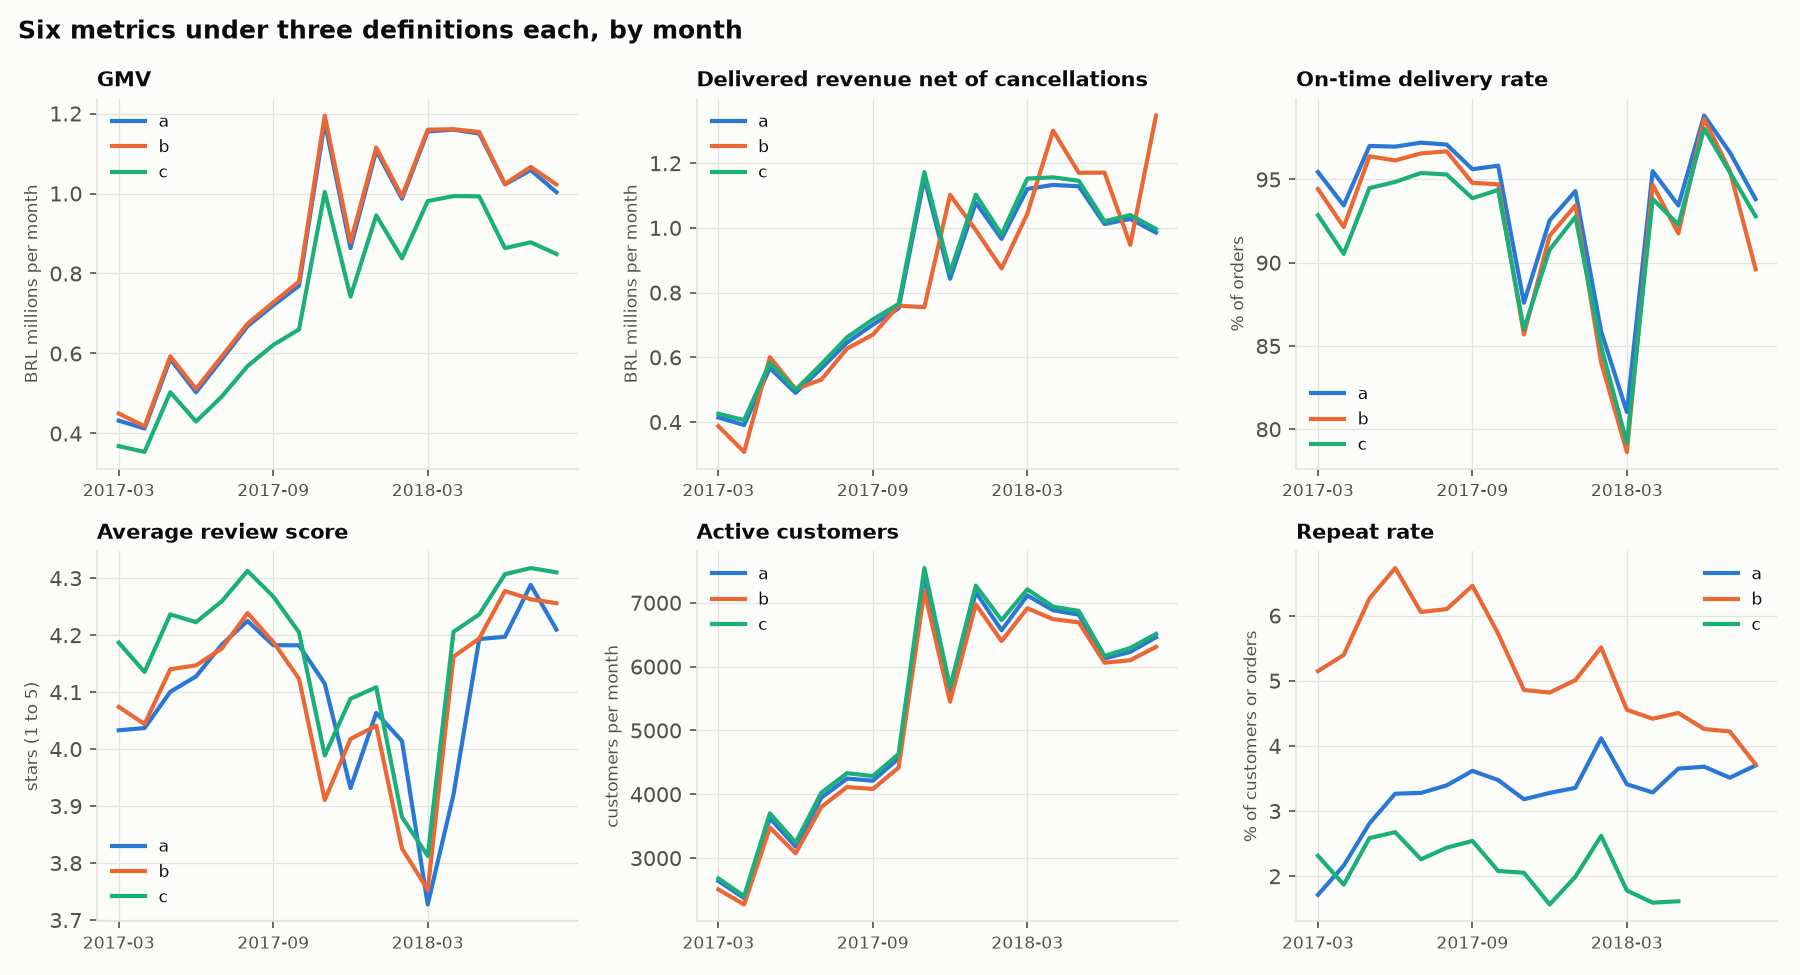

max_divergence_by_metric from divergence() + plot_divergence()


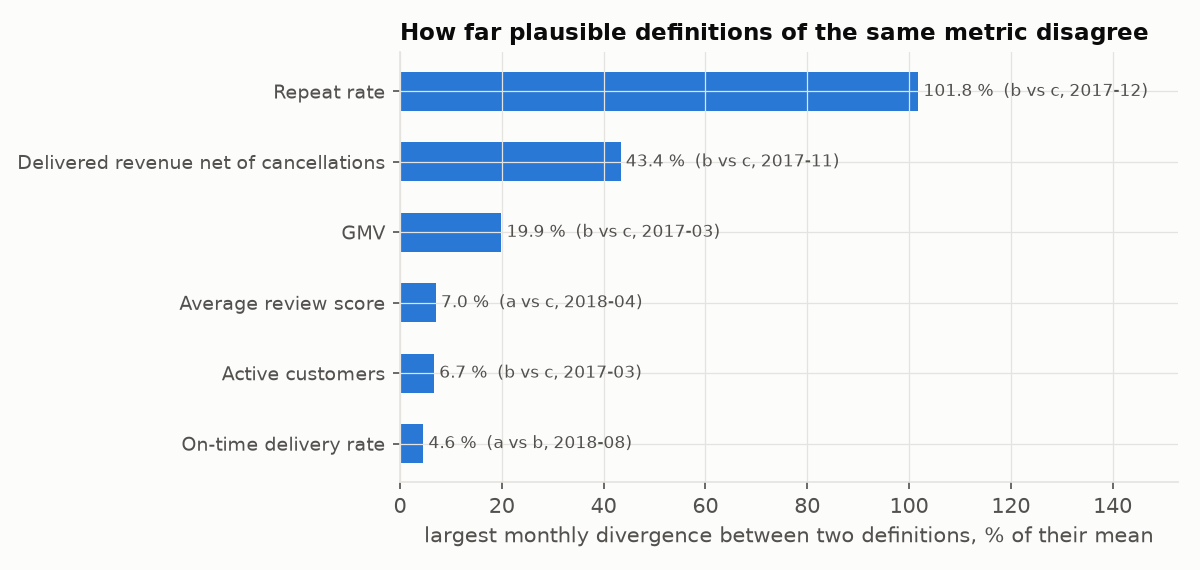

In [6]:
for key, fig in res["figures"].items():
    print(key, "from", fig["source"])
    display(Image(filename=str(RESULTS.parent / fig["file"])))